In [17]:
import tensorflow
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [18]:
model = Sequential()

In [19]:
model.add( Dense(3, activation='sigmoid', input_dim=11 ))
model.add(Dense(1, activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(loss="binary_crossentropy", optimizer="Adam", metrics=["accuracy"])

In [22]:
# This cell is cleared to resolve the AttributeError.
# To inspect training history, use the history object returned from a .fit() call, such as 'model1.fit(...)'.
print("First model compiled successfully. To get history, train it first with model.fit()")

First model compiled successfully. To get history, train it first with model.fit()


In [23]:
from tensorflow.keras.layers import Flatten

In [24]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

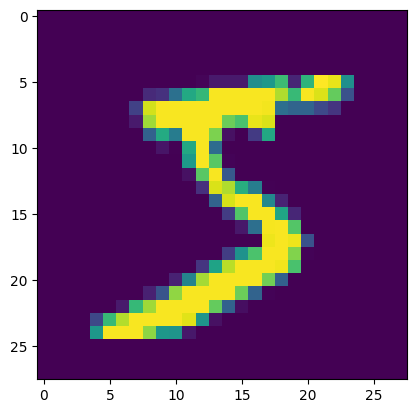

In [25]:
X_train.shape
from matplotlib import pyplot as plt
plt.imshow(X_train[0])

In [26]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [27]:
model1 = Sequential()
model1.add(Flatten(input_shape=(28, 28)))
model1.add(Dense(100, activation="relu"))
model1.add(Dense(10, activation="softmax"))
model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [29]:
model1.compile(loss="sparse_categorical_crossentropy", optimizer="Adam", metrics=["accuracy"])

In [30]:
history = model1.fit(X_train_scaled, y_train, epochs=5, validation_split=0.2)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9154 - loss: 0.2983 - val_accuracy: 0.9534 - val_loss: 0.1638
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9611 - loss: 0.1342 - val_accuracy: 0.9642 - val_loss: 0.1196
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9730 - loss: 0.0913 - val_accuracy: 0.9673 - val_loss: 0.1101
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9793 - loss: 0.0711 - val_accuracy: 0.9731 - val_loss: 0.0955
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9836 - loss: 0.0555 - val_accuracy: 0.9688 - val_loss: 0.1046


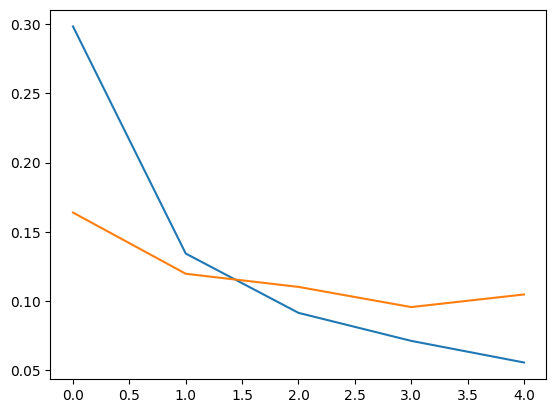

In [31]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

In [32]:
model1.layers[2].get_weights()

[array([[-4.62154150e-01,  2.74833590e-01,  1.72875643e-01,
         -1.28263161e-01, -1.33082315e-01,  1.31611507e-02,
         -6.35279894e-01,  2.05367446e-01,  5.46913333e-02,
          1.16715021e-01],
        [ 1.54043511e-01, -2.82644987e-01, -2.23424494e-01,
         -1.23691104e-01, -2.53987551e-01,  1.45171180e-01,
          2.99389243e-01, -4.70261902e-01,  1.62762329e-01,
         -3.62042077e-02],
        [-2.11668134e-01, -5.02253234e-01,  5.56747522e-03,
         -3.31083596e-01, -4.59411621e-01,  7.57763922e-01,
          4.20706362e-01,  3.66810352e-01,  5.72032481e-02,
         -6.01195753e-01],
        [-2.38045290e-01, -2.73566931e-01, -1.08142637e-01,
          1.07835509e-01, -2.14239699e-04, -2.65616924e-01,
         -3.67662013e-01,  4.45600972e-02,  1.21473879e-01,
          5.99566214e-02],
        [ 1.87666088e-01, -1.60832226e-01,  2.34816924e-01,
          1.06626689e-01, -3.76774341e-01, -4.63456273e-01,
          4.73938324e-02,  3.03685844e-01, -8.721566

In [33]:
# ============================================
# ANN Regression using Keras
# ============================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

# California Housing dataset
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

# print(df.head())
print(df.shape)


# --------------------------------------------
# 2. Prepare Data
# --------------------------------------------

# Remove categorical column
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True)

# Remove rows containing missing values
df = df.dropna()

# Features
X = df.drop("median_house_value", axis=1)

# Target
y = df["median_house_value"]


# --------------------------------------------
# 3. Train-Test Split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# --------------------------------------------
# 4. Feature Scaling
# --------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# --------------------------------------------
# 5. Build ANN
# --------------------------------------------

model = Sequential([

    # Hidden Layer 1
    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),

    # Hidden Layer 2
    Dense(32, activation="relu"),

    # Output Layer
    Dense(1, activation="linear")
])


# --------------------------------------------
# 6. Compile Model
# --------------------------------------------

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# --------------------------------------------
# 7. Train Model
# --------------------------------------------

history = model.fit(
    X_train,
    y_train,
    epochs=2,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


# --------------------------------------------
# 8. Prediction
# --------------------------------------------

y_pred = model.predict(X_test)


# --------------------------------------------
# 9. Evaluation
# --------------------------------------------

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)


# --------------------------------------------
# 10. Compare Actual vs Predicted
# --------------------------------------------

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.flatten()
})

print(results[["Actual", "Predicted"]].head(10))

(20640, 10)
Epoch 1/2


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


409/409 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 55684657152.0000 - mae: 206183.5938 - val_loss: 55799373824.0000 - val_mae: 206107.2500
Epoch 2/2
409/409 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 53566898176.0000 - mae: 201819.7969 - val_loss: 51704025088.0000 - val_mae: 197612.8906
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MSE: 52042055351.85612
MAE: 197914.36336478693
R2 Score: -2.8055844501119127
     Actual     Predicted
0  245800.0  16326.471680
1  137900.0   7461.483887
2  218200.0   5431.905273
3  220800.0  14783.178711
4  170500.0   1843.783813
5   75000.0   5671.308105
6  269400.0   7614.207520
7  228900.0  12149.041016
8  500001.0  21096.642578
9   80800.0   3613.395020


X_train.shape

In [34]:
X_train.shape

(16346, 12)

In [35]:
# ==========================================
# 1. Import Libraries
# ==========================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ==========================================
# 2. Load Dataset
# ==========================================

data = load_breast_cancer()

X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", data.target_names)


# ==========================================
# 3. Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ==========================================
# 4. Feature Scaling
# ==========================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ==========================================
# 5. Build ANN Model
# ==========================================

model = Sequential([

    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])


# ==========================================
# 6. Compile Model
# ==========================================

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# ==========================================
# 7. Early Stopping
# ==========================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


# ==========================================
# 8. Train Model
# ==========================================

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


# ==========================================
# 9. Evaluate Model
# ==========================================

loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)


# ==========================================
# 10. Prediction
# ==========================================

y_probability = model.predict(X_test)

# Convert probabilities into 0 or 1
y_pred = (y_probability >= 0.5).astype(int)


# ==========================================
# 11. Classification Report
# ==========================================

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

X shape: (569, 30)
y shape: (569,)
Classes: ['malignant' 'benign']
Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7170 - loss: 0.5890 - val_accuracy: 0.9231 - val_loss: 0.3383
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8571 - loss: 0.3457 - val_accuracy: 0.9560 - val_loss: 0.2226
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9396 - loss: 0.2308 - val_accuracy: 0.9670 - val_loss: 0.1716
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9368 - loss: 0.1991 - val_accuracy: 0.9670 - val_loss: 0.1406
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9588 - loss: 0.1618 - val_accuracy: 0.9670 - val_loss: 0.1165
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9588 - loss: 0.1347 - val_accuracy: 0.9780 - val_loss: 0.1010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9478 - loss: 0.1410 - val_accuracy: 0.9780 - val_loss: 0.0905
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9753 - loss: 0.1098 - val_accuracy: 0.9780 - val_loss